# Partie C : Régression linéaire, prévision du temps de remplissage

**Objectif :** estimer la vitesse de remplissage des bennes et prévoir le temps restant avant qu'elles soient pleines.

**Données :** fichier `digital_twin_time_series_dataset.csv` (dataset Kaggle « Smart Waste IoT & Computer Vision »), 304 bennes, 4 mesures chacune entre 08:00 et 08:30. Données simulées.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Chargement et préparation
base = "/kaggle/input/datasets/ajithdari/smart-waste-iot-and-computer-vision-dataset/Dataset/"
df = pd.read_csv(base + "digital_twin_time_series_dataset.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"], dayfirst=True)
df = df.sort_values(["bin_id", "timestamp"]).reset_index(drop=True)

# Minutes écoulées depuis la première mesure (variable explicative)
df["minutes"] = (df["timestamp"] - df["timestamp"].min()).dt.total_seconds() / 60

# Niveau de la benne à 08:00
df["niveau_initial"] = df.groupby("bin_id")["fill_level"].transform("first")

# Une benne "en remplissage" est une benne dont le niveau augmente nettement
variation = df.groupby("bin_id")["fill_level"].transform(lambda s: s.iloc[-1] - s.iloc[0])
df["en_remplissage"] = variation > 5

print("Bennes en remplissage :", df.loc[df["en_remplissage"], "bin_id"].nunique())
print("Bennes déjà pleines  :", df.loc[~df["en_remplissage"], "bin_id"].nunique())

Bennes en remplissage : 133
Bennes déjà pleines  : 171


## Entraînement
On ne garde que les bennes qui se remplissent (133). Le modèle de régression linéaire prédit `fill_level` à partir du temps écoulé et du niveau initial. Découpage temporel : entraînement sur 08:00 à 08:20, test sur 08:30.

In [14]:
# 2. Découpage temporel : train = 08:00 à 08:20, test = 08:30
remp = df[df["en_remplissage"]].copy()
train = remp[remp["minutes"] <= 20]
test = remp[remp["minutes"] == 30]

features = ["minutes", "niveau_initial"]
model = LinearRegression()
model.fit(train[features], train["fill_level"])

LinearRegression()

In [15]:
# 3. Évaluation
pred = model.predict(test[features])
mae = mean_absolute_error(test["fill_level"], pred)
rmse = np.sqrt(mean_squared_error(test["fill_level"], pred))
r2 = r2_score(test["fill_level"], pred)
print(f"\nMAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.4f}")
print("Vitesse de remplissage apprise (points/minute) :", round(model.coef_[0], 3))


MAE  : 1.000
RMSE : 1.000
R²   : -0.6975
Vitesse de remplissage apprise (points/minute) : 2.15


## Évaluation sur des bennes non vues
Le test à 08:30 a très peu de dispersion, ce qui rend le R² négatif malgré une erreur de 1 point seulement. On évalue donc aussi le modèle sur 20 % de bennes jamais vues pendant l'entraînement.

In [16]:
from sklearn.model_selection import train_test_split

bennes = remp["bin_id"].unique()
b_train, b_test = train_test_split(bennes, test_size=0.2, random_state=42)

tr = remp[remp["bin_id"].isin(b_train)]
te = remp[remp["bin_id"].isin(b_test)]

m2 = LinearRegression().fit(tr[features], tr["fill_level"])
p2 = m2.predict(te[features])

print("MAE  :", round(mean_absolute_error(te["fill_level"], p2), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(te["fill_level"], p2)), 3))
print("R²   :", round(r2_score(te["fill_level"], p2), 4))

MAE  : 0.6
RMSE : 0.671
R²   : 0.9992


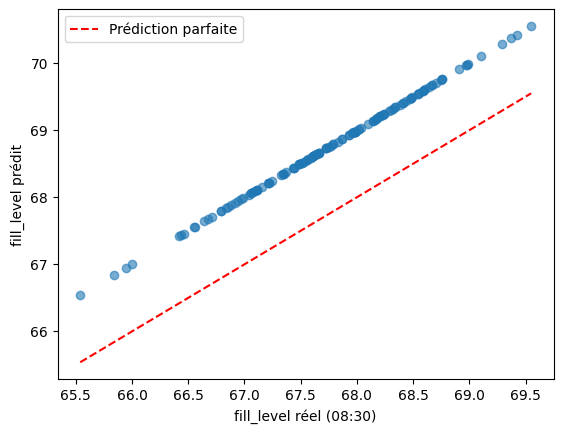

In [17]:
# 4. Graphique : valeurs prédites vs réelles à 08:30
plt.scatter(test["fill_level"], pred, alpha=0.6)
lim = [test["fill_level"].min(), test["fill_level"].max()]
plt.plot(lim, lim, "r--", label="Prédiction parfaite")
plt.xlabel("fill_level réel (08:30)")
plt.ylabel("fill_level prédit")
plt.legend()
plt.show()

In [18]:
# 5. Temps restant avant que la benne soit pleine
SEUIL = 85  # niveau considéré comme "plein" (à discuter avec le groupe)
vitesse = model.coef_[0]
niveau_08h30 = test.set_index("bin_id")["fill_level"]
temps_restant = (SEUIL - niveau_08h30) / vitesse
print(f"\nTemps restant avant d'atteindre {SEUIL} (en minutes) :")
print(temps_restant.describe())


Temps restant avant d'atteindre 85 (en minutes) :
count    133.000000
mean       8.012310
std        0.358340
min        7.186047
25%        7.758140
50%        8.013953
75%        8.255814
max        9.051163
Name: fill_level, dtype: float64


## Résultats et limites
- Vitesse de remplissage apprise : environ 2,15 points par minute.
- Sur des bennes non vues : MAE 0,6, RMSE 0,67, R² 0,999.
- Temps restant avant le seuil de 85 : environ 8 minutes en moyenne.

**Limites :** données simulées, vitesse presque constante pour toutes les bennes, 30 minutes de mesures seulement. Le temps restant est donc une extrapolation et non une valeur vérifiée.